# The Regularized Rotational Vector Field (RRVF) Model
## Reproducible numerical audit: amplitude envelope, discrete energy balance, grid refinement

**Author:** Mounir Djebassi · ORCID 0009-0009-6871-7693 · October 2026

This notebook accompanies the manuscript *The Regularized Rotational Vector Field (RRVF) Model: A Universal Amplitude Envelope and a Reproducible Numerical Audit*. It is deterministic (no random numbers) and runs in well under a minute on a laptop.

**Model (1D periodic, three components, advection velocity $T_1$):**
$$\partial_t T + T_1\,\partial_x T = \nu\,\partial_{xx} T + \Omega\times T - \gamma\,\|T\|^{2n}\,T,\qquad \Omega=(0,0,1).$$

**Scope.** This is a reduced one-dimensional vector system. It has no pressure and no divergence-free constraint, and it is **not** the three-dimensional Navier–Stokes system. No regularity claim for gradients is made.

**Contents.** (1) scheme and bookkeeping, (2) three-grid audit, (3) consistency checks, (4) successive-grid differences, (5) figures, (6) export of results used in the manuscript.

In [1]:
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python", platform.python_version(), "| NumPy", np.__version__, "| pandas", pd.__version__, "| Matplotlib", matplotlib.__version__)

PARAMS = dict(nu=0.05, gamma=0.5, n=1, omega_z=1.0, t_end=1.0, t_shock=0.75, shock_amp=6.0)
GRIDS = (200, 400, 800)
print(PARAMS)

Python 3.12.3 | NumPy 2.4.4 | pandas 3.0.2 | Matplotlib 3.10.8
{'nu': 0.05, 'gamma': 0.5, 'n': 1, 'omega_z': 1.0, 't_end': 1.0, 't_shock': 0.75, 'shock_amp': 6.0}


## 1. Scheme and bookkeeping

* Domain $[-1,1)$, period 2, $N_x$ points, $\Delta x = 2/N_x$; periodic centred differences for $\partial_x T$ and $\partial_{xx}T$; explicit forward Euler.
* Time step $\Delta t=\min(0.25\,\Delta x^2/\nu,\;0.4\,\Delta x/u_{\max})$ with $u_{\max}=\max_x|T_1(x,0)|+6$, then rescaled so that $t=1$ is reached exactly.
* At the first time level with $t\ge 0.75$ the pulse $\Delta T_1(x)=6\exp[-\sin^2(\pi x/2)/0.1^2]$ is added to the first component; the energy jump is measured directly.
* Discrete energy $E=\tfrac{\Delta x}{2}\sum_j |T_j|^2$. For $T^{k+1}=T^k+\Delta t\,F(T^k)$ the identity
$$E^{k+1}-E^{k}=\Delta t\,\Delta x\sum_j T^k_j\!\cdot\!F^k_j+\tfrac{\Delta t^{2}\Delta x}{2}\sum_j|F^k_j|^2$$
holds exactly. The audit accumulates the four physical rates **and** the Euler term $\tfrac{\Delta t^2\Delta x}{2}\sum|F|^2$.
* Amplitude envelope after the pulse, restarted from the measured post-pulse amplitude $M_0$ at the actual injection time $t_{\rm inj}$ (valid for **any** $n\ge 1$):
$$M(t)\le M_0\,\bigl[1+2n\gamma M_0^{2n}(t-t_{\rm inj})\bigr]^{-1/(2n)} .$$
The universal envelope, independent of $M_0$, is $\bigl[2n\gamma(t-t_{\rm inj})\bigr]^{-1/(2n)}$.

In [2]:
def envelope(M0, tau, gamma, n):
    # amplitude envelope restarted from M0 after elapsed time tau (general n)
    return M0 / (1.0 + 2.0*n*gamma*M0**(2*n)*tau)**(1.0/(2*n))

def universal_envelope(tau, gamma, n):
    # limit M0 -> infinity: independent of the initial amplitude
    return (2.0*n*gamma*tau)**(-1.0/(2*n))

def energy(T, dx):
    return 0.5*dx*np.sum(T**2)

def simulate(nx, nu, gamma, n, omega_z, t_end, t_shock, shock_amp, dt_cap=None, keep_profiles=False):
    dx = 2.0/nx
    x = -1.0 + dx*np.arange(nx)
    T = np.zeros((3, nx))
    T[0] = 3.0*np.exp(-np.sin(np.pi*x/2.0)**2/0.15**2)
    T[1] = 1.5*np.exp(-np.sin(np.pi*(x-0.2)/2.0)**2/0.12**2)
    # third component is zero initially

    u_max = np.abs(T[0]).max() + shock_amp
    dt_adv, dt_dif = 0.4*dx/u_max, 0.25*dx**2/nu
    regime = "advection" if dt_adv < dt_dif else "diffusion"
    dt = min(dt_adv, dt_dif)
    if dt_cap is not None:
        dt = min(dt, dt_cap)
    nsteps = int(np.ceil(t_end/dt - 1e-8))
    dt = t_end/nsteps

    E0 = energy(T, dx)
    rates = dict(diffusion=0.0, advection=0.0, rotation=0.0, damping=0.0)
    euler_term = 0.0
    jump = 0.0
    injected, t_inj, M0_post = False, None, None
    t_hist = np.empty(nsteps + 1); M_hist = np.empty(nsteps + 1)
    t_hist[0] = 0.0; M_hist[0] = np.sqrt((T**2).sum(0)).max()
    min_margin = np.inf
    T1_max, M_max_post = np.abs(T[0]).max(), 0.0
    prof = {}

    for k in range(nsteps):
        t = k*dt
        if (not injected) and t >= t_shock - 1e-12:
            if keep_profiles:
                prof["pre"] = T.copy()
            Eb = energy(T, dx)
            T[0] += shock_amp*np.exp(-np.sin(np.pi*x/2.0)**2/0.1**2)
            jump = energy(T, dx) - Eb
            injected, t_inj = True, t
            M0_post = np.sqrt((T**2).sum(0)).max()
            if keep_profiles:
                prof["post"] = T.copy()

        Tp, Tm = np.roll(T, -1, axis=1), np.roll(T, 1, axis=1)
        Tx = (Tp - Tm)/(2.0*dx)
        Txx = (Tp - 2.0*T + Tm)/dx**2

        adv = -T[0]*Tx
        dif = nu*Txx
        rot = np.vstack([-omega_z*T[1], omega_z*T[0], np.zeros(nx)])   # Omega x T, Omega=(0,0,omega_z)
        nrm2 = (T**2).sum(0)
        dmp = -gamma*nrm2**n*T
        F = dif + adv + rot + dmp

        rates["diffusion"] += dt*dx*np.sum(T*dif)
        rates["advection"] += dt*dx*np.sum(T*adv)
        rates["rotation"]  += dt*dx*np.sum(T*rot)
        rates["damping"]   += dt*dx*np.sum(T*dmp)
        euler_term += 0.5*dt**2*dx*np.sum(F**2)

        T = T + dt*F
        M = np.sqrt((T**2).sum(0)).max()
        t_hist[k+1] = (k+1)*dt; M_hist[k+1] = M
        T1_max = max(T1_max, np.abs(T[0]).max())
        if injected:
            M_max_post = max(M_max_post, M)
            margin = envelope(M0_post, (k+1)*dt - t_inj, gamma, n) - M
            min_margin = min(min_margin, margin)

    E1 = energy(T, dx)
    dE = E1 - E0
    rate_sum = sum(rates.values())
    resid_raw = abs(dE - (rate_sum + jump))
    resid_corrected = abs(dE - (rate_sum + jump + euler_term))
    tau_end = t_end - t_inj
    out = dict(nx=nx, dx=dx, dt=dt, nsteps=nsteps, regime=regime, t_inj=t_inj,
               E0=E0, E1=E1, dE=dE, jump=jump, rates=rates, rate_sum=rate_sum,
               euler_term=euler_term, resid_raw=resid_raw, resid_corrected=resid_corrected,
               M0_post=M0_post, M_end=M_hist[-1], bound_end=envelope(M0_post, tau_end, gamma, n),
               universal_end=universal_envelope(tau_end, gamma, n), min_margin=min_margin,
               bound_ok=bool(min_margin >= -1e-12), T1_max=T1_max, M_max_post=M_max_post,
               T_final=T.copy(), x=x, t_hist=t_hist, M_hist=M_hist)
    if keep_profiles:
        prof["final"] = T.copy(); out["profiles"] = prof
    return out

## 2. Three-grid audit

In [3]:
res = {nx: simulate(nx, **PARAMS, keep_profiles=(nx == 800)) for nx in GRIDS}

rows = []
for nx, r in res.items():
    rows.append({"Nx": nx, "dt": f"{r['dt']:.5e}", "limiting": r["regime"], "t_inj": f"{r['t_inj']:.6f}",
                 "E(0)": f"{r['E0']:.4f}", "E(1)": f"{r['E1']:.4f}", "dE measured": f"{r['dE']:+.6f}",
                 "pulse jump": f"{r['jump']:+.4f}", "rates+jump": f"{r['rate_sum']+r['jump']:+.6f}",
                 "residual": f"{r['resid_raw']:.4e}", "residual/dt": f"{r['resid_raw']/r['dt']:.2f}",
                 "Euler term": f"{r['euler_term']:.4e}", "residual after Euler term": f"{r['resid_corrected']:.2e}"})
energy_table = pd.DataFrame(rows).set_index("Nx")
print("DISCRETE ENERGY AUDIT")
display(energy_table.T)

rows = []
for nx, r in res.items():
    tau = PARAMS["t_end"] - r["t_inj"]
    rows.append({"Nx": nx, "M0 post-pulse": f"{r['M0_post']:.6f}", "M(1)": f"{r['M_end']:.6f}",
                 "restarted envelope at t=1": f"{r['bound_end']:.6f}", "universal envelope at t=1": f"{r['universal_end']:.6f}",
                 "min margin over steps": f"{r['min_margin']:.3e}", "envelope respected": r["bound_ok"]})
amp_table = pd.DataFrame(rows).set_index("Nx")
print("AMPLITUDE AUDIT AFTER THE PULSE")
display(amp_table.T)

DISCRETE ENERGY AUDIT


Nx,200,400,800
dt,4.44444e-04,1.25000e-04,3.12500e-05
limiting,advection,diffusion,diffusion
t_inj,0.750222,0.750000,0.750000
E(0),0.6480,0.6480,0.6480
E(1),0.2870,0.2878,0.2880
dE measured,-0.361031,-0.360262,-0.360018
pulse jump,+1.6021,+1.6023,+1.6023
rates+jump,-0.387772,-0.367617,-0.361844
residual,2.6741e-02,7.3546e-03,1.8262e-03
residual/dt,60.17,58.84,58.44


AMPLITUDE AUDIT AFTER THE PULSE


Nx,200,400,800
M0 post-pulse,6.246590,6.246800,6.246840
M(1),1.200839,1.201671,1.202055
restarted envelope at t=1,1.905520,1.904758,1.904759
universal envelope at t=1,2.000889,2.000000,2.000000
min margin over steps,6.716e-02,1.892e-02,4.731e-03
envelope respected,True,True,True


## 3. Consistency checks

1. **Rotation is energy-neutral:** $\sum_k \Delta t\,\Delta x\sum_j T\cdot(\Omega\times T)$ vanishes to round-off.
2. **Bookkeeping closes exactly** once the Euler term is included (round-off level).
3. **Residual scales like $\Delta t$:** the ratio residual$/\Delta t$ is nearly constant.
4. **Time-step conditions** (frozen-coefficient von Neumann analysis of explicit Euler with centred advection–diffusion, plus the damping stiffness): $\Delta t\le \Delta x^2/(2\nu)$, $\Delta t\le 2\nu/u^2$, $\Delta t\le 2/\bigl((2n+1)\gamma M^{2n}\bigr)$. These are necessary conditions for the linearised problems, not a proof of stability for the full nonlinear scheme.
5. **General $n$:** the envelope code path is not specialised to $n=1$; it is exercised with $n=2$.

In [4]:
n = PARAMS["n"]; nu = PARAMS["nu"]; gamma = PARAMS["gamma"]
checks = {}
for nx, r in res.items():
    c = {}
    c["rotation_rate_abs"] = abs(r["rates"]["rotation"])
    c["closure_after_euler"] = r["resid_corrected"]
    c["residual_over_dt"] = r["resid_raw"]/r["dt"]
    c["dt_over_diffusion_limit"] = r["dt"]/(r["dx"]**2/(2*nu))
    c["dt_over_advection_limit"] = r["dt"]/(2*nu/r["T1_max"]**2)
    c["dt_over_damping_limit"] = r["dt"]/(2.0/((2*n+1)*gamma*r["M_max_post"]**(2*n)))
    checks[nx] = c
    assert c["rotation_rate_abs"] < 1e-12
    assert c["closure_after_euler"] < 1e-12
    assert max(c["dt_over_diffusion_limit"], c["dt_over_advection_limit"], c["dt_over_damping_limit"]) < 1.0
    assert r["bound_ok"]
print(pd.DataFrame(checks).to_string(float_format=lambda v: f"{v:.3e}"))

# general-n exercise (n = 2): finer step so that the damping stiffness condition is satisfied
r2 = simulate(400, **{**PARAMS, "n": 2}, dt_cap=2.5e-5)
print(f"\nn=2, Nx=400: dt={r2['dt']:.3e}, M0_post={r2['M0_post']:.4f}, M(1)={r2['M_end']:.6f}, "
      f"envelope={r2['bound_end']:.6f}, respected={r2['bound_ok']}, closure after Euler term={r2['resid_corrected']:.2e}")
assert r2["bound_ok"] and r2["resid_corrected"] < 1e-12
print("\nAll checks passed.")

                              200       400       800
rotation_rate_abs       4.461e-19 4.591e-19 1.188e-19
closure_after_euler     2.498e-15 1.776e-15 2.331e-15
residual_over_dt        6.017e+01 5.884e+01 5.844e+01
dt_over_diffusion_limit 4.444e-01 5.000e-01 5.000e-01
dt_over_advection_limit 1.665e-01 4.818e-02 1.214e-02
dt_over_damping_limit   1.251e-02 3.619e-03 9.121e-04



n=2, Nx=400: dt=2.500e-05, M0_post=6.2441, M(1)=0.913861, envelope=1.188816, respected=True, closure after Euler term=8.72e-15

All checks passed.


## 4. Successive-grid differences (exploratory)

Differences are evaluated at coincident sample points at $t=1$. The $L^2$ difference is $\bigl(\Delta x_c\sum_j |\delta T_j|^2\bigr)^{1/2}$ with $\Delta x_c$ the coarser spacing; the vector $L^\infty$ difference is $\max_j|\delta T_j|$ (Euclidean norm over components). The apparent order is $p=\log_2(D_{200\text{–}400}/D_{400\text{–}800})$.

Caveats: space and time are refined together; $N_x=200$ is advection-limited while $N_x=400,800$ are diffusion-limited; the pulse is injected at $t_{\rm inj}=0.750222$ for $N_x=200$ and at $0.75$ for the other two. The orders are therefore **exploratory**, not asymptotic rates.

In [5]:
T200, T400, T800 = (res[k]["T_final"] for k in GRIDS)
d1, d2 = T200 - T400[:, ::2], T400 - T800[:, ::2]
def l2(d, dxc): return np.sqrt(dxc*np.sum(d**2))
def linf(d):    return np.sqrt((d**2).sum(0)).max()
D = {"L2": (l2(d1, 2/200), l2(d2, 2/400)), "Linf": (linf(d1), linf(d2))}
cauchy = {k: dict(D_200_400=v[0], D_400_800=v[1], p=float(np.log2(v[0]/v[1]))) for k, v in D.items()}
print(pd.DataFrame(cauchy).T.to_string(float_format=lambda v: f"{v:.6e}" if abs(v) < 0.1 else f"{v:.4f}"))

        D_200_400    D_400_800      p
L2   1.366138e-03 3.637092e-04 1.9092
Linf 3.219469e-03 5.518278e-04 2.5445


## 5. Figures

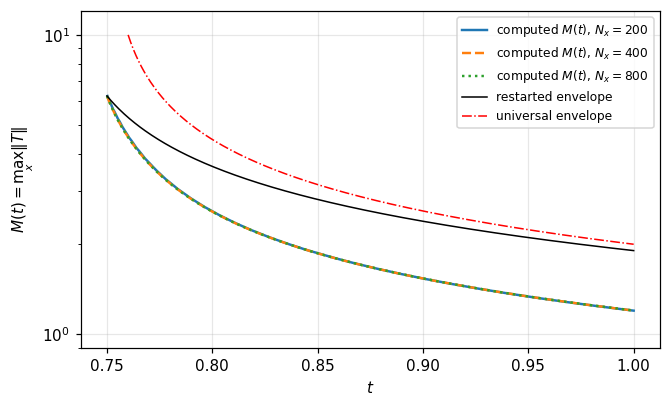

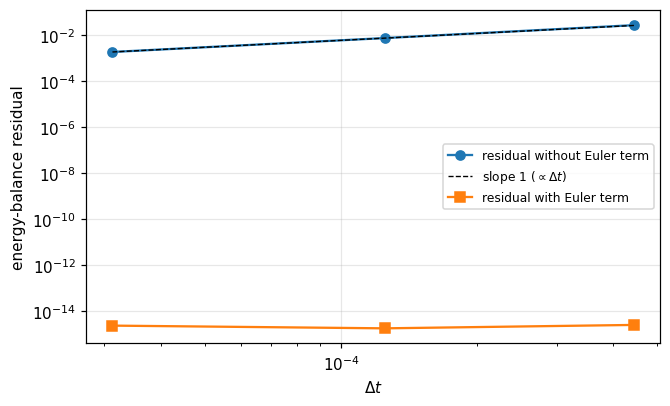

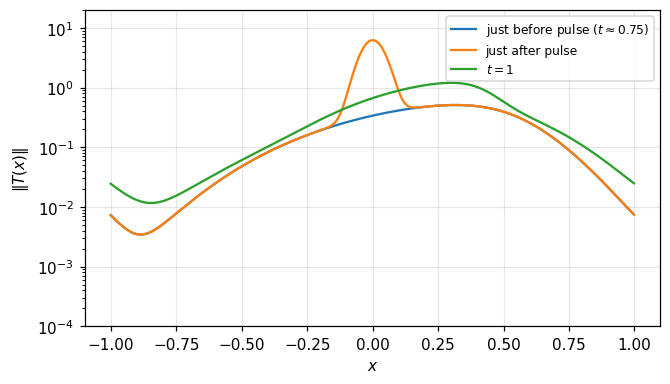

In [6]:
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

# Figure 1: amplitude after the pulse versus envelopes
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for nx, ls in zip(GRIDS, ("-", "--", ":")):
    r = res[nx]; m = r["t_hist"] > r["t_inj"] + 1e-12
    ax.semilogy(np.r_[r["t_inj"], r["t_hist"][m]], np.r_[r["M0_post"], r["M_hist"][m]], ls, lw=1.6, label=f"computed $M(t)$, $N_x={nx}$")
r = res[800]; tt = np.linspace(r["t_inj"], 1.0, 400)
ax.semilogy(tt, envelope(r["M0_post"], tt - r["t_inj"], gamma, n), "k-", lw=1.0, label="restarted envelope")
tu = tt[tt - r["t_inj"] >= 0.01]
ax.semilogy(tu, universal_envelope(tu - r["t_inj"], gamma, n), "r-.", lw=1.0, label="universal envelope")
ax.set_ylim(0.9, 12); ax.set_xlabel("$t$"); ax.set_ylabel(r"$M(t)=\max_x\|T\|$"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig_amplitude.pdf"); fig.savefig("figures/fig_amplitude.png", dpi=200); plt.show()

# Figure 2: energy residual versus time step
fig, ax = plt.subplots(figsize=(6.2, 3.8))
dts = np.array([res[k]["dt"] for k in GRIDS])
raw = np.array([res[k]["resid_raw"] for k in GRIDS]); cor = np.array([max(res[k]["resid_corrected"], 1e-17) for k in GRIDS])
ax.loglog(dts, raw, "o-", label="residual without Euler term")
ax.loglog(dts, raw[-1]*(dts/dts[-1]), "k--", lw=0.9, label=r"slope 1 ($\propto \Delta t$)")
ax.loglog(dts, cor, "s-", label="residual with Euler term")
ax.set_xlabel(r"$\Delta t$"); ax.set_ylabel("energy-balance residual"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig_residual.pdf"); fig.savefig("figures/fig_residual.png", dpi=200); plt.show()

# Figure 3: norm profiles before the pulse, right after the pulse, and at t = 1 ($N_x=800$)
p = res[800]["profiles"]; x = res[800]["x"]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for key, lab in (("pre", "just before pulse ($t\\approx0.75$)"), ("post", "just after pulse"), ("final", "$t=1$")):
    ax.semilogy(x, np.sqrt((p[key]**2).sum(0)) + 1e-16, label=lab)
ax.set_xlabel("$x$"); ax.set_ylabel(r"$\|T(x)\|$"); ax.set_ylim(1e-4, 20); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig_profiles.pdf"); fig.savefig("figures/fig_profiles.png", dpi=200); plt.show()

## 6. Export of the numbers quoted in the manuscript

In [7]:
export = {"params": PARAMS, "grids": {}, "cauchy": cauchy, "checks": {str(k): v for k, v in checks.items()},
          "n2_check": {k: (float(v) if isinstance(v, (float, np.floating)) else v)
                       for k, v in r2.items() if k in ("dt", "M0_post", "M_end", "bound_end", "bound_ok", "resid_corrected")}}
for nx, r in res.items():
    export["grids"][str(nx)] = {k: (float(v) if isinstance(v, (float, np.floating, int)) and not isinstance(v, bool) else v)
                                for k, v in r.items() if k in ("nx", "dx", "dt", "nsteps", "regime", "t_inj", "E0", "E1", "dE", "jump",
                                "rate_sum", "euler_term", "resid_raw", "resid_corrected", "M0_post", "M_end", "bound_end",
                                "universal_end", "min_margin", "bound_ok", "T1_max", "M_max_post")}
    export["grids"][str(nx)]["rates"] = {k: float(v) for k, v in r["rates"].items()}
with open("results_rrvf.json", "w") as f:
    json.dump(export, f, indent=2)
print("Saved results_rrvf.json and figures/*.pdf, figures/*.png")

Saved results_rrvf.json and figures/*.pdf, figures/*.png
